In [1]:
# Q6B: Q-learning Taxi problem on a simple 5x5 grid.
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# The agent must pick up at (0, 0) and drop off at (4, 4).
# State: taxi row, taxi column, passenger on board (0/1).
pickup, destination = (0, 0), (4, 4)
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
action_names = ["up", "down", "left", "right", "pick up", "drop off"]
def step(state, action):
    row, col, onboard = state
    reward, done = -1, False
    if action < 4:
        dr, dc = moves[action]
        row = int(np.clip(row + dr, 0, 4))
        col = int(np.clip(col + dc, 0, 4))
    elif action == 4:
        if (row, col) == pickup and onboard == 0:
            onboard, reward = 1, 5
        else:
            reward = -10
    elif action == 5:
        if (row, col) == destination and onboard == 1:
            reward, done = 20, True
        else:
            reward = -10
    return (row, col, onboard), reward, done


In [3]:
# Train from random taxi positions, with an empty taxi each episode.
rng = np.random.default_rng(42)
q = np.zeros((5, 5, 2, 6))
alpha, gamma = 0.2, 0.95
successes = []
for episode in range(8000):
    state = (int(rng.integers(5)), int(rng.integers(5)), 0)
    epsilon = max(0.05, 1 - episode / 6000)
    done = False
    for _ in range(100):
        action = int(rng.integers(6)) if rng.random() < epsilon else int(np.argmax(q[state]))
        next_state, reward, done = step(state, action)
        target = reward if done else reward + gamma * np.max(q[next_state])
        q[state][action] += alpha * (target - q[state][action])
        state = next_state
        if done:
            break
    successes.append(done)
print("Completion rate in final 100 episodes:", round(np.mean(successes[-100:]), 3))


Completion rate in final 100 episodes: 1.0


(4, 0, 0) -> up -> (3, 0, 0) reward: -1
(3, 0, 0) -> up -> (2, 0, 0) reward: -1
(2, 0, 0) -> up -> (1, 0, 0) reward: -1
(1, 0, 0) -> up -> (0, 0, 0) reward: -1
(0, 0, 0) -> pick up -> (0, 0, 1) reward: 5
(0, 0, 1) -> down -> (1, 0, 1) reward: -1
(1, 0, 1) -> down -> (2, 0, 1) reward: -1
(2, 0, 1) -> down -> (3, 0, 1) reward: -1
(3, 0, 1) -> down -> (4, 0, 1) reward: -1
(4, 0, 1) -> right -> (4, 1, 1) reward: -1
(4, 1, 1) -> right -> (4, 2, 1) reward: -1
(4, 2, 1) -> right -> (4, 3, 1) reward: -1
(4, 3, 1) -> right -> (4, 4, 1) reward: -1
(4, 4, 1) -> drop off -> (4, 4, 1) reward: 20
Passenger delivered: True


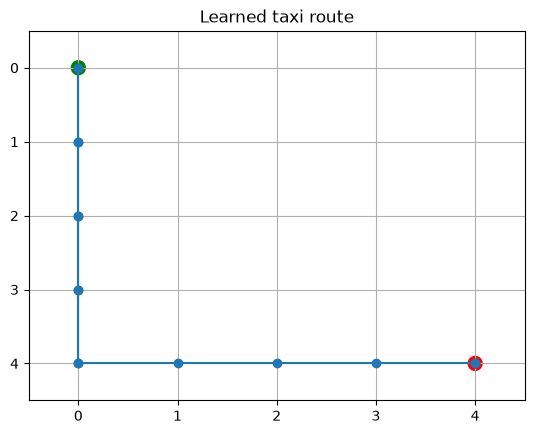

In [4]:
# Test one trip: start at (4, 0), collect the passenger, then drop off.
state = (4, 0, 0)
trip = [state]
for _ in range(50):
    action = int(np.argmax(q[state]))
    next_state, reward, done = step(state, action)
    print(state, "->", action_names[action], "->", next_state, "reward:", reward)
    state = next_state
    trip.append(state)
    if done:
        break
print("Passenger delivered:", done)
assert done, "Increase the training episodes if the policy has not converged."
coordinates = np.array([(row, col) for row, col, _ in trip])
plt.plot(coordinates[:, 1], coordinates[:, 0], marker="o")
plt.scatter([pickup[1], destination[1]], [pickup[0], destination[0]],
            c=["green", "red"], s=100, label="Pickup / destination")
plt.xlim(-0.5, 4.5); plt.ylim(4.5, -0.5)
plt.xticks(range(5)); plt.yticks(range(5))
plt.title("Learned taxi route")
plt.grid(); plt.show()
